# BRFSS — Model Training, Evaluation & Explainability

**Inputs:**
- `newdata/brfss2015_clean_binary.csv` — 253,680 records  
- `newdata/brfss2017_clean_binary.csv` — 275,746 records → combined for train + validation  
- `newdata/brfss2019_clean_binary.csv` — 240,493 records → independent test set

**Pipeline (9 sections):**
```
1. Data Loading  →  2. Combine & Split (85/15)  →  3. SMOTE (train only)
  →  4. Model Training (5 classifiers)  →  5. Threshold Tuning
  →  6. Test Evaluation (2019)  →  7. XAI / SHAP
  →  8. Gemini AI  →  9. Output (risk tiers + dashboard + save)
```
**Saves:** `best_model_brfss.pkl` · `scaler_brfss.pkl` · `threshold_brfss.pkl` · `feature_names_brfss.pkl`

## 1. Data Loading & Configuration

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from dotenv import load_dotenv
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
TARGET_COL   = 'Diabetes_binary'
DATA_DIR     = '../newdata/'

USE_SAMPLE   = True
SAMPLE_N     = 40_000

FEATURE_GROUPS = {
    'Health Status':                 ['BMI','HighBP','HighChol','CholCheck','Stroke',
                                      'HeartDiseaseorAttack','GenHlth','PhysHlth',
                                      'MentHlth','DiffWalk'],
    'Lifestyle & Healthcare Access': ['Smoker','HvyAlcoholConsump','PhysActivity',
                                      'Fruits','Veggies','AnyHealthcare','NoDocbcCost'],
    'Demographic':                   ['Sex','Age','Education','Income'],
}

FEATURE_LABELS = {
    'HighBP': 'High blood pressure', 'HighChol': 'High cholesterol',
    'CholCheck': 'Cholesterol check', 'BMI': 'BMI',
    'Smoker': 'Smoker', 'Stroke': 'Stroke history',
    'HeartDiseaseorAttack': 'Heart disease/attack',
    'PhysActivity': 'Physical activity', 'Fruits': 'Fruit consumption',
    'Veggies': 'Vegetable consumption', 'HvyAlcoholConsump': 'Heavy alcohol use',
    'AnyHealthcare': 'Has healthcare', 'NoDocbcCost': 'No doc due to cost',
    'GenHlth': 'General health', 'MentHlth': 'Mental health days',
    'PhysHlth': 'Physical health days', 'DiffWalk': 'Difficulty walking',
    'Sex': 'Sex', 'Age': 'Age group', 'Education': 'Education level', 'Income': 'Income level',
}

RISK_COLORS = {'Low': '#4CAF50', 'Moderate': '#FF9800', 'High': '#F44336'}

print('Libraries loaded.')
print(f'Mode: {"SAMPLE (" + str(SAMPLE_N) + " per year)" if USE_SAMPLE else "FULL DATASET"}')

### 1.1 Load BRFSS 2015 + 2017 (Train/Validation Pool)

In [3]:
print('Loading BRFSS 2015...')
df15 = pd.read_csv(DATA_DIR + 'brfss2015_clean_binary.csv')
print(f'  2015: {df15.shape}  |  diabetes rate: {df15[TARGET_COL].mean()*100:.1f}%')

print('Loading BRFSS 2017...')
df17 = pd.read_csv(DATA_DIR + 'brfss2017_clean_binary.csv')
print(f'  2017: {df17.shape}  |  diabetes rate: {df17[TARGET_COL].mean()*100:.1f}%')

combined = pd.concat([df15, df17], ignore_index=True)
print(f'Combined: {combined.shape}  |  diabetes rate: {combined[TARGET_COL].mean()*100:.1f}%')

Loading BRFSS 2015...
  2015: (253680, 22)  |  diabetes rate: 13.9%
Loading BRFSS 2017...
  2017: (275746, 22)  |  diabetes rate: 16.0%
Combined: (529426, 22)  |  diabetes rate: 15.0%


### 1.2 Load BRFSS 2019 (Independent Test Set)

In [4]:
print('Loading BRFSS 2019 (independent test)...')
df19 = pd.read_csv(DATA_DIR + 'brfss2019_clean_binary.csv')
print(f'  2019: {df19.shape}  |  diabetes rate: {df19[TARGET_COL].mean()*100:.1f}%')

X_test_raw = df19.drop(columns=[TARGET_COL])
y_test     = df19[TARGET_COL]
FEATURES   = X_test_raw.columns.tolist()
print(f'Features ({len(FEATURES)}): {FEATURES}')

Loading BRFSS 2019 (independent test)...
  2019: (240493, 22)  |  diabetes rate: 16.9%
Features (21): ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


## 2. Combine & Split — Stratified 85/15 (within 2015+2017)

Train on 85 % of the combined 2015+2017 pool; hold out 15 % for validation.  
BRFSS 2019 is kept as the **independent test set** and is never touched during training.

                           Rows  Diabetes  No Diabetes  % Positive
Split                                                             
Train (2015+2017 85%)    450012     67436       382576        15.0
Val  (2015+2017 15%)      79414     11900        67514        15.0
Test (2019 independent)  240493     40586       199907        16.9


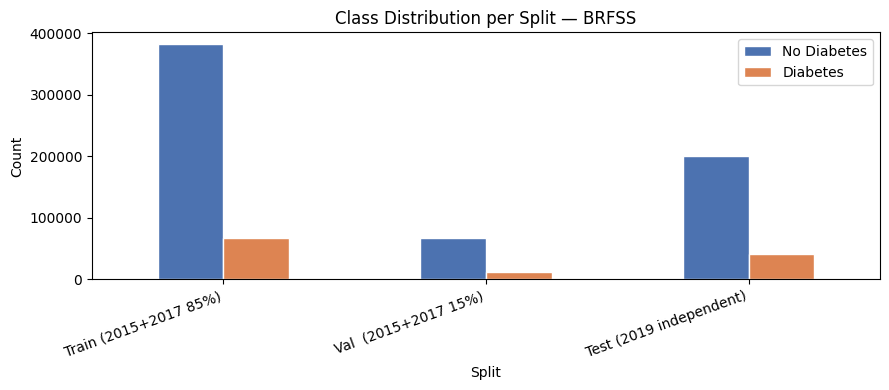

In [5]:
X = combined.drop(columns=[TARGET_COL])
y = combined[TARGET_COL]

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)

summary = pd.DataFrame([
    {'Split': n, 'Rows': len(s), 'Diabetes': int(s.sum()),
     'No Diabetes': int((s==0).sum()), '% Positive': round(s.mean()*100, 1)}
    for n, s in [('Train (2015+2017 85%)', y_train),
                 ('Val  (2015+2017 15%)', y_val),
                 ('Test (2019 independent)', y_test)]
]).set_index('Split')
print(summary)

summary[['No Diabetes','Diabetes']].plot(
    kind='bar', figsize=(9, 4), color=['#4C72B0','#DD8452'], edgecolor='white'
)
plt.title('Class Distribution per Split — BRFSS')
plt.ylabel('Count'); plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.show()

## 2. (continued) Feature Scaling

StandardScaler fit on train only, then applied to val and test.

In [6]:
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train_raw)
X_val_s   = scaler.transform(X_val_raw)
X_test_s  = scaler.transform(X_test_raw)
print(f'Scaled — Train: {X_train_s.shape}  Val: {X_val_s.shape}  Test: {X_test_s.shape}')

Scaled — Train: (450012, 21)  Val: (79414, 21)  Test: (240493, 21)


## 3. SMOTE — Balance the Training Set

SMOTE creates synthetic minority-class samples **inside the training set only**.  
Validation and test sets remain untouched real data — metrics reflect true real-world performance.

                 Before SMOTE  After SMOTE
Diabetes_binary                           
No Diabetes            382576       382576
Diabetes                67436       382576


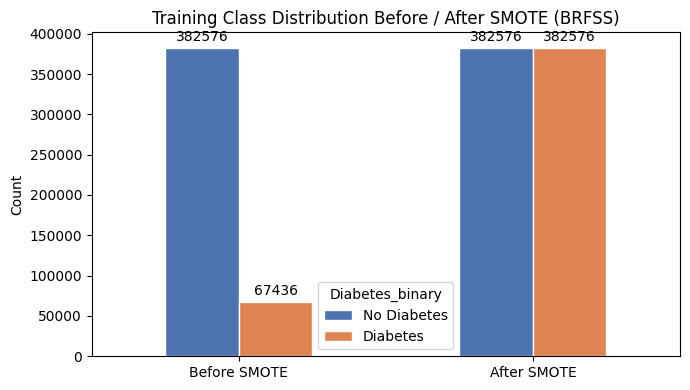

In [7]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_s, y_train)

before = pd.Series(y_train).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
after  = pd.Series(y_train_bal).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
smote_df = pd.DataFrame({'Before SMOTE': before, 'After SMOTE': after})
print(smote_df)

ax = smote_df.T.plot(kind='bar', figsize=(7, 4),
                     color=['#4C72B0','#DD8452'], edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.title('Training Class Distribution Before / After SMOTE (BRFSS)')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 4. Model Training — 4 Individual Models

Train each model independently on the SMOTE-balanced training set.  
The ensemble will be built **after** validation evaluation, using only the top 3 performers.

In [ ]:
# ── Step 0: Define/train individual models ───────────────────────────────
individual_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_split=5, min_samples_leaf=1, max_depth=None, class_weight="balanced", random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, subsample=0.8, learning_rate=0.2, use_label_encoder=False, eval_metric="logloss", random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(n_estimators=300, max_depth=-1, learning_rate=0.1, class_weight="balanced", random_state=RANDOM_STATE)
}

# Convert scaled arrays back to DataFrames for feature names
X_val_s_df = pd.DataFrame(X_val_s, columns=X_train_raw.columns)
X_train_s_df = pd.DataFrame(X_train_s, columns=X_train_raw.columns)
X_test_s_df  = pd.DataFrame(X_test_s, columns=X_train_raw.columns)

# Fit all models on balanced training data
for name, model in individual_models.items():
    model.fit(X_train_bal, y_train_bal)
    print(f"Trained: {name}")

# ── Step 1: Evaluate all 4 individual models ─────────────────────────────
indiv_results = {n: evaluate(m, X_val_s_df, y_val) for n, m in individual_models.items()}
indiv_df = pd.DataFrame(indiv_results).T.sort_values('F1', ascending=False)
print('Individual Model Validation Results (sorted by F1):')
print(indiv_df.to_string())

# ── Step 2: Select top 3 by F1 ───────────────────────────────────────────
top3_names = indiv_df.nlargest(3, 'F1').index.tolist()
print(f'\nTop 3 selected for ensemble  →  {top3_names}')
print(f'  (based on highest validation F1  +  Recall  +  ROC-AUC)')

# ── Step 3: Build Soft Voting Ensemble from top 3 ───────────────────────
ensemble = VotingClassifier(
    estimators=[(n.lower().replace(' ','_').replace('/','_'), individual_models[n]) for n in top3_names],
    voting='soft', n_jobs=-1
)
ensemble.fit(X_train_bal, y_train_bal)
ensemble_label = f'Ensemble ({" + ".join(n.split()[0] for n in top3_names)})'
print(f'Soft Voting Ensemble built: {ensemble_label}')

# ── Step 4: Final candidates — top 3 individual + ensemble ──────────────
final_models = {n: individual_models[n] for n in top3_names}
final_models[ensemble_label] = ensemble

final_results = {n: evaluate(m, X_val_s_df, y_val) for n, m in final_models.items()}
val_df = pd.DataFrame(final_results).T.sort_values('F1', ascending=False)
print('\nFinal Candidates Validation Results (sorted by F1):')
print(val_df.to_string())
print('\nMain metric: F1  |  Healthcare metric: Recall  |  Support: ROC-AUC, Accuracy, Precision')

# ── Plot comparison ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

val_df[['F1','Recall','ROC-AUC']].plot(kind='bar', ax=axes[0],
    color=['#1976D2','#DD8452','#55A868'], edgecolor='white')
axes[0].set_title('Final Candidate Comparison — Validation Set', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].set_ylim(0, 1.05)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].legend(loc='lower right')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.3f', fontsize=7, padding=2)

val_df['F1'].sort_values().plot(kind='barh', ax=axes[1], color='#1976D2', edgecolor='white')
axes[1].set_title('F1-Score Ranking (Primary Selection Metric)', fontweight='bold')
axes[1].set_xlabel('Validation F1-Score')
axes[1].axvline(val_df['F1'].max(), color='red', linestyle='--', linewidth=1.2, label='Best F1')
axes[1].legend()
for i, (idx, row) in enumerate(val_df['F1'].sort_values().items()):
    axes[1].text(row + 0.002, i, f'{row:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## 4. (continued) Model Selection & Ensemble Building

**Step 1** — Evaluate all 4 individual models on the validation set.  
**Step 2** — Select the **top 3** by validation F1-score (primary) + Recall + ROC-AUC.  
**Step 3** — Build a Soft Voting Ensemble from those 3 models.  
**Step 4** — Compare all 4 final candidates (top-3 individual + ensemble) and pick the winner by **validation F1**.

In [ ]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred  = (proba >= threshold).astype(int)
    return {
        'Accuracy':  round(accuracy_score(y, pred), 4),
        'Precision': round(precision_score(y, pred, zero_division=0), 4),
        'Recall':    round(recall_score(y, pred, zero_division=0), 4),
        'F1':        round(f1_score(y, pred, zero_division=0), 4),
        'ROC-AUC':   round(roc_auc_score(y, proba), 4),
    }

# ── Step 1: Evaluate all 4 individual models ──────────────────────────────────
indiv_results = {n: evaluate(m, X_val_s, y_val) for n, m in individual_models.items()}
indiv_df = pd.DataFrame(indiv_results).T.sort_values('F1', ascending=False)
print('Individual Model Validation Results (sorted by F1):')
print(indiv_df.to_string())

# ── Step 2: Select top 3 by F1 ────────────────────────────────────────────────
top3_names = indiv_df.nlargest(3, 'F1').index.tolist()
print(f'\nTop 3 selected for ensemble  →  {top3_names}')
print(f'  (based on highest validation F1  +  Recall  +  ROC-AUC)')

# ── Step 3: Build Soft Voting Ensemble from top 3 ─────────────────────────────
ensemble = VotingClassifier(
    estimators=[(n.lower().replace(' ','_').replace('/','_'), individual_models[n])
                for n in top3_names],
    voting='soft', n_jobs=1
)
ensemble.fit(X_train_bal, y_train_bal)
ensemble_label = f'Ensemble ({" + ".join(n.split()[0] for n in top3_names)})'
print(f'Soft Voting Ensemble built: {ensemble_label}')

# ── Step 4: Final candidates — top 3 individual + ensemble ───────────────────
final_models = {n: individual_models[n] for n in top3_names}
final_models[ensemble_label] = ensemble

final_results = {n: evaluate(m, X_val_s, y_val) for n, m in final_models.items()}
val_df = pd.DataFrame(final_results).T.sort_values('F1', ascending=False)
print('\nFinal Candidates Validation Results (sorted by F1):')
print(val_df.to_string())
print('\nMain metric: F1  |  Healthcare metric: Recall  |  Support: ROC-AUC, Accuracy, Precision')

# ── Plot comparison ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

val_df[['F1','Recall','ROC-AUC']].plot(kind='bar', ax=axes[0],
    color=['#1976D2','#DD8452','#55A868'], edgecolor='white')
axes[0].set_title('Final Candidate Comparison — Validation Set', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].set_ylim(0, 1.05)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].legend(loc='lower right')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.3f', fontsize=7, padding=2)

val_df['F1'].sort_values().plot(kind='barh', ax=axes[1], color='#1976D2', edgecolor='white')
axes[1].set_title('F1-Score Ranking (Primary Selection Metric)', fontweight='bold')
axes[1].set_xlabel('Validation F1-Score')
axes[1].axvline(val_df['F1'].max(), color='red', linestyle='--', linewidth=1.2, label='Best F1')
axes[1].legend()
for i, (idx, row) in enumerate(val_df['F1'].sort_values().items()):
    axes[1].text(row + 0.002, i, f'{row:.4f}', va='center', fontsize=9)

plt.tight_layout(); plt.show()

## 5. Threshold Tuning

Select best model by ROC-AUC, then sweep decision thresholds to maximise **Recall** subject to F1 ≥ 0.35.  
In screening, missing a true diabetic is more costly than a false alarm.

In [ ]:
# Best model selected by highest validation F1 (primary metric)
best_name  = val_df['F1'].idxmax()
best_model = final_models[best_name]
print(f'Best model selected: {best_name}')
print(f'  Val F1      : {val_df.loc[best_name,"F1"]:.4f}   ← primary selection metric')
print(f'  Val Recall  : {val_df.loc[best_name,"Recall"]:.4f}')
print(f'  Val ROC-AUC : {val_df.loc[best_name,"ROC-AUC"]:.4f}')

F1_FLOOR  = 0.35
proba_val = best_model.predict_proba(X_val_s)[:, 1]
thr_rows  = []
for t in np.arange(0.05, 0.95, 0.01):
    pred = (proba_val >= t).astype(int)
    thr_rows.append({'Threshold': round(t,2),
                     'Recall':    recall_score(y_val, pred, zero_division=0),
                     'Precision': precision_score(y_val, pred, zero_division=0),
                     'F1':        f1_score(y_val, pred, zero_division=0)})
thr_df     = pd.DataFrame(thr_rows)
acceptable = thr_df[thr_df['F1'] >= F1_FLOOR]

if len(acceptable) == 0:
    chosen_threshold = 0.5
    print(f'No threshold meets F1>={F1_FLOOR}. Using 0.5.')
else:
    best_thr = acceptable.loc[acceptable['Recall'].idxmax()]
    chosen_threshold = best_thr['Threshold']
    print(f'\nChosen threshold : {chosen_threshold:.2f}')
    print(f'  Recall         : {best_thr["Recall"]:.4f}')
    print(f'  Precision      : {best_thr["Precision"]:.4f}')
    print(f'  F1             : {best_thr["F1"]:.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thr_df['Threshold'], thr_df['Recall'],    label='Recall',    color='#DD8452')
ax.plot(thr_df['Threshold'], thr_df['Precision'], label='Precision', color='#4C72B0')
ax.plot(thr_df['Threshold'], thr_df['F1'],        label='F1',        color='#55A868')
ax.axvline(chosen_threshold, color='red', linestyle='--', label=f'Chosen ({chosen_threshold:.2f})')
ax.axhline(F1_FLOOR, color='gray', linestyle=':', label=f'F1 floor ({F1_FLOOR})')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold Sweep on Validation Set')
ax.legend(); plt.tight_layout(); plt.show()

## 6. Test Evaluation — Independent BRFSS 2019

In [ ]:
proba_test = best_model.predict_proba(X_test_s)[:, 1]
y_pred     = (proba_test >= chosen_threshold).astype(int)

test_metrics = {
    'Accuracy':  accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall':    recall_score(y_test, y_pred, zero_division=0),
    'F1':        f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_test, proba_test),
}
print(f'Independent Test (BRFSS 2019) — {best_name}  (threshold={chosen_threshold:.2f})')
for k, v in test_metrics.items():
    print(f'  {k:<12s} {v:.4f}')
print()
print(classification_report(y_test, y_pred, target_names=['No Diabetes','Diabetes']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Diabetes','Diabetes']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {best_name} (2019 Test)')

for name, m in final_models.items():
    p = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    lw  = 2.5 if name == best_name else 1.0
    axes[1].plot(fpr, tpr, lw=lw, label=f'{name} (AUC={auc:.3f})')
axes[1].plot([0,1],[0,1],'k--', alpha=0.4)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves — 2019 Independent Test (final candidates)')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. XAI — SHAP Explainability

Using a 500-row sample for SHAP computation at scale.  
TreeExplainer is used for tree models; if best model is LR or Ensemble, SHAP runs on the LightGBM component.

In [ ]:
TREE_MODELS = ['LightGBM','XGBoost','Random Forest']

if best_name in TREE_MODELS:
    shap_model = best_model
    shap_model_name = best_name
else:
    # Fall back to the best tree model among individual models
    tree_candidates = [n for n in TREE_MODELS if n in individual_models]
    shap_model_name = indiv_df.loc[indiv_df.index.isin(tree_candidates), 'F1'].idxmax()
    shap_model = individual_models[shap_model_name]
    shap_model_name += ' (SHAP proxy — best tree)'

print(f'SHAP computed on: {shap_model_name}')

shap_idx    = np.random.RandomState(RANDOM_STATE).choice(len(X_test_s), min(500, len(X_test_s)), replace=False)
X_shap      = X_test_s[shap_idx]
explainer   = shap.TreeExplainer(shap_model)
shap_values = explainer(X_shap)

if shap_values.values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

print(f'SHAP values shape: {sv.values.shape}')

mean_shap     = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=True)
labels_mapped = [FEATURE_LABELS.get(f, f) for f in mean_shap.index]
palette       = ['#DD8452' if v > mean_shap.median() else '#4C72B0' for v in mean_shap]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(labels_mapped, mean_shap.values, color=palette)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('Global Feature Importance — BRFSS')
plt.tight_layout(); plt.show()

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('SHAP Beeswarm — BRFSS Test Patients')
plt.tight_layout(); plt.show()

## 8. Gemini AI — Setup & Recommendations

Gemini API is loaded from `.env` and used to convert model outputs into plain-language lifestyle education.  
Gemini does **not** diagnose — it only explains what the model found.

In [ ]:
from google import genai

load_dotenv('../.env')
GEMINI_API_KEY = os.getenv('GEMINI_API_KEY', '')
gemini_client  = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None

def get_gemini_recommendations(prob, risk, patient_profile, top_risk_factors, protective_factors):
    payload = {
        'risk_probability': round(float(prob), 2), 'risk_level': risk,
        'patient_profile': patient_profile, 'top_risk_factors': top_risk_factors,
        'protective_factors': protective_factors,
        'instruction': 'Provide simple lifestyle education only. Do not diagnose.',
    }
    prompt = (
        'You are a friendly health educator. Based on this diabetes risk assessment, '
        'provide lifestyle guidance.\n\n' + json.dumps(payload, indent=2)
        + '\n\nRespond ONLY in this JSON (no markdown):\n'
        '{"explanation": "...", "recommendations": ["...","...","...","..."], '
        '"safety_reminder": "..."}'
    )
    try:
        r = gemini_client.models.generate_content(model='gemini-1.5-flash', contents=prompt)
        text = r.text.strip()
        if '```' in text:
            text = text.split('```')[1]
            if text.startswith('json'): text = text[4:]
        return json.loads(text.strip())
    except Exception:
        return {
            'explanation': f'Predicted risk: {prob*100:.0f}% ({risk} level).',
            'recommendations': [
                'Maintain a balanced diet rich in vegetables and whole grains',
                'Engage in at least 150 minutes of moderate exercise per week',
                'Monitor blood pressure and blood glucose regularly',
                'Consult a healthcare professional for personalised advice',
            ],
            'safety_reminder': 'For educational awareness only — not a medical diagnosis.',
        }

print(f'Gemini client ready: {"Yes" if gemini_client else "No API key set"}')

Gemini client ready: Yes


## 9. Output — Risk Categories, Patient Dashboard & Save

| Risk Level | Probability |
|---|---|
| Low | < 30 % |
| Moderate | 30 % – 70 % |
| High | ≥ 70 % |

In [ ]:
def risk_label(prob):
    return 'High' if prob >= 0.70 else ('Moderate' if prob >= 0.30 else 'Low')

test_report = X_test_raw.copy().reset_index(drop=True)
test_report['True Label']  = y_test.values
test_report['Probability'] = proba_test.round(3)
test_report['Risk Level']  = test_report['Probability'].apply(risk_label)
test_report['Prediction']  = y_pred

risk_dist = test_report['Risk Level'].value_counts().reindex(['Low','Moderate','High'])
print('Risk distribution on Test Set (BRFSS 2019):')
print(risk_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for lab, grp in test_report.groupby('True Label'):
    axes[0].hist(grp['Probability'], bins=30, alpha=0.65,
                 label=['No Diabetes','Diabetes'][int(lab)], density=True)
axes[0].axvline(0.30, color='orange', linestyle='--', label='30% cutoff')
axes[0].axvline(0.70, color='red',    linestyle='--', label='70% cutoff')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_title('Probability Distribution by True Class')
axes[0].legend()

risk_dist.plot(kind='bar', ax=axes[1],
               color=[RISK_COLORS[r] for r in risk_dist.index], edgecolor='white')
for p in axes[1].patches:
    axes[1].annotate(str(int(p.get_height())),
                     (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
axes[1].set_title('Risk Tier Distribution — 2019 Test Set')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(risk_dist.index, rotation=0)
plt.tight_layout(); plt.show()

### 9.2 Patient Dashboard (4-Panel)

Four-panel per-patient report: probability gauge · SHAP drivers · group insight donut · Gemini recommendations.

High-risk example: SHAP sample #308


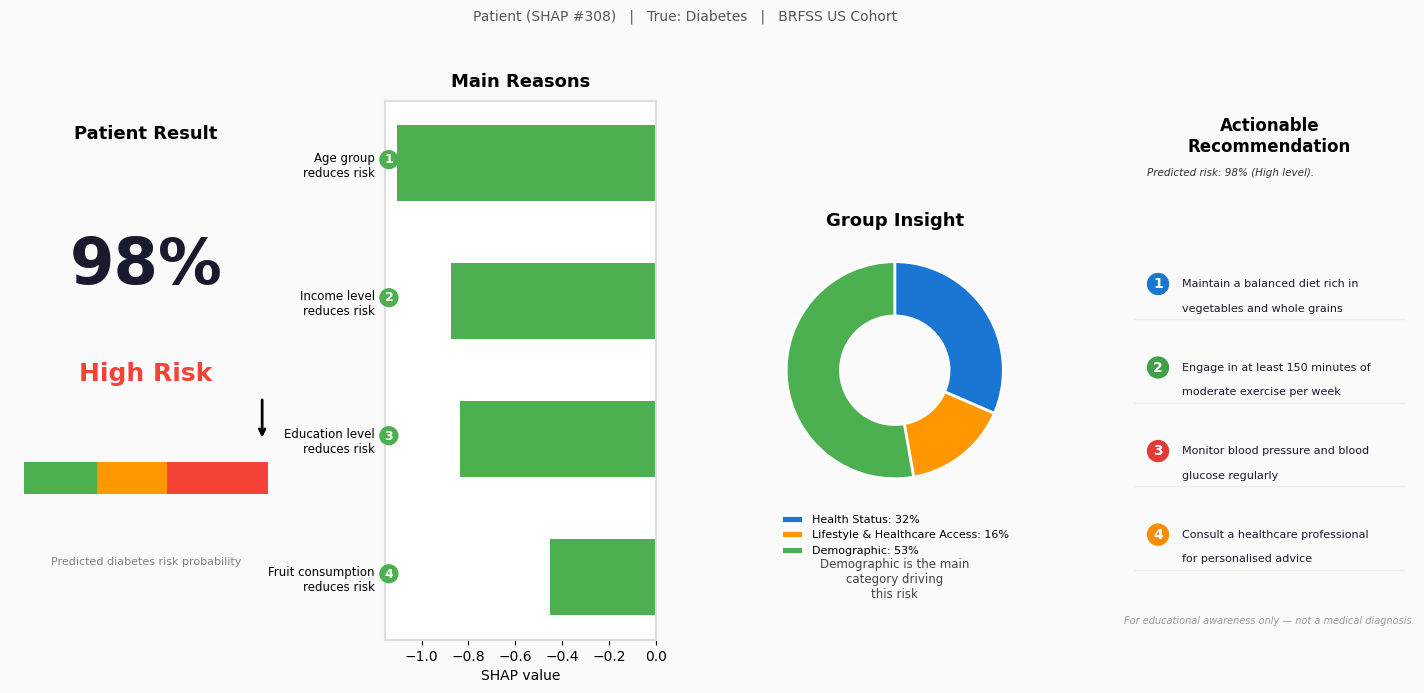

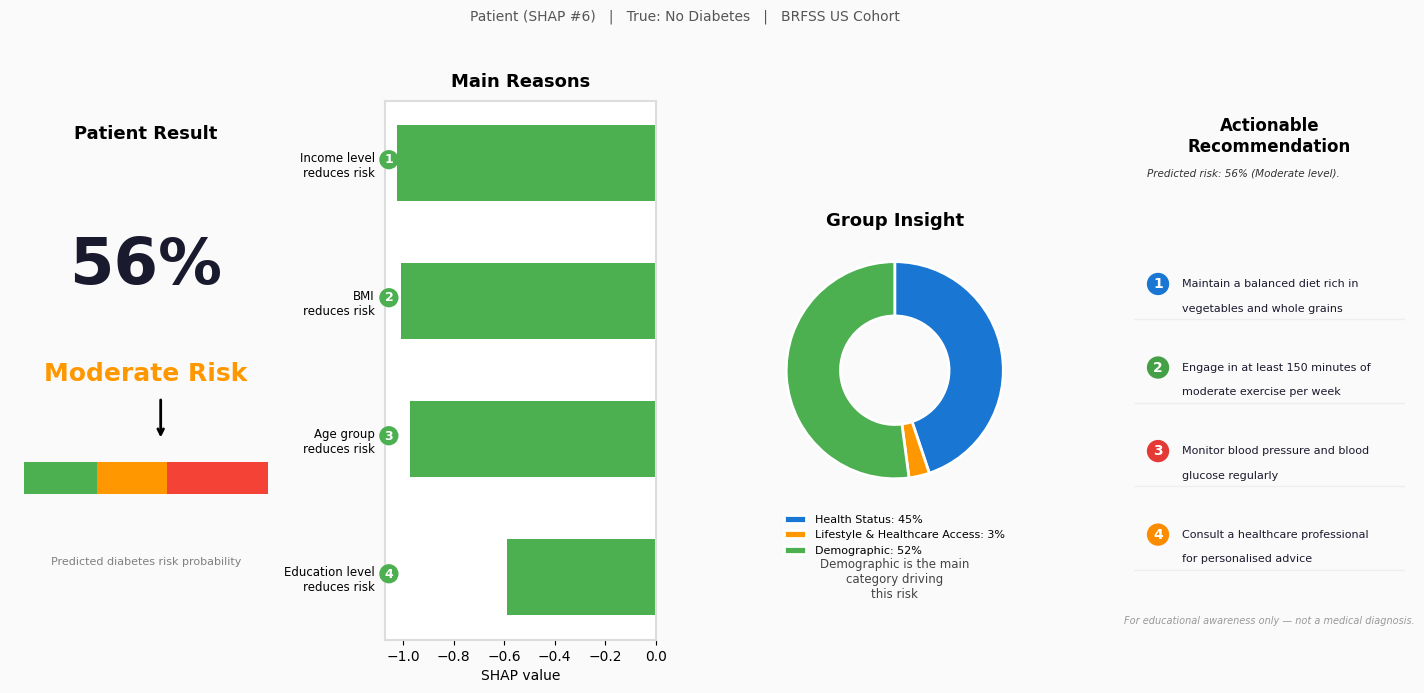

In [ ]:
proba_shap = proba_test[shap_idx]

def patient_dashboard_brfss(local_idx, use_gemini=True):
    prob       = float(proba_shap[local_idx])
    risk       = risk_label(prob)
    true_label = int(y_test.values[shap_idx[local_idx]])
    shap_vals  = sv.values[local_idx]
    row        = X_test_raw.iloc[shap_idx[local_idx]]

    order     = np.argsort(np.abs(shap_vals))[::-1]
    top_feats = [FEATURES[i] for i in order[:4]]
    top_vals  = [shap_vals[i] for i in order[:4]]

    gc = {}
    for grp, feats in FEATURE_GROUPS.items():
        idxs = [FEATURES.index(f) for f in feats if f in FEATURES]
        gc[grp] = float(np.abs(shap_vals[idxs]).sum())
    gc_total = sum(gc.values()) or 1
    gc_pct   = {k: v/gc_total*100 for k, v in gc.items()}

    risk_feats = [FEATURE_LABELS.get(FEATURES[i], FEATURES[i])
                  for i in np.argsort(shap_vals)[::-1][:4] if shap_vals[i] > 0]
    prot_feats = [FEATURE_LABELS.get(FEATURES[i], FEATURES[i])
                  for i in np.argsort(shap_vals)[:4] if shap_vals[i] < 0]
    patient_profile = {
        'Age': int(row.get('Age', 0)), 'BMI': round(float(row.get('BMI', 0)), 1),
        'HighBP': int(row.get('HighBP', 0)), 'GenHlth': int(row.get('GenHlth', 0)),
        'PhysActive': int(row.get('PhysActivity', 0)), 'Smoker': int(row.get('Smoker', 0)),
    }

    if use_gemini and gemini_client:
        gem = get_gemini_recommendations(prob, risk, patient_profile, risk_feats, prot_feats)
    else:
        gem = {
            'explanation': f'Predicted risk: {prob*100:.0f}% ({risk} level).',
            'recommendations': [
                'Maintain a balanced diet with more vegetables and whole grains',
                'Exercise at least 150 minutes per week',
                'Monitor blood pressure and blood sugar regularly',
                'Consult a healthcare professional for personalised advice',
            ],
            'safety_reminder': 'For educational awareness only — not a medical diagnosis.',
        }
    recs = gem.get('recommendations', [])[:4]

    risk_color   = RISK_COLORS[risk]
    group_colors = ['#1976D2','#FF9800','#4CAF50']

    fig = plt.figure(figsize=(18, 7))
    fig.patch.set_facecolor('#FAFAFA')
    gs  = fig.add_gridspec(1, 4, wspace=0.38)

    ax1 = fig.add_subplot(gs[0]); ax1.set_facecolor('white'); ax1.axis('off')
    ax1.text(0.5, 0.93, 'Patient Result', ha='center', fontsize=13, fontweight='bold', transform=ax1.transAxes)
    ax1.text(0.5, 0.66, f'{prob*100:.0f}%', ha='center', fontsize=46, fontweight='bold', color='#1A1A2E', transform=ax1.transAxes)
    ax1.text(0.5, 0.48, f'{risk} Risk', ha='center', fontsize=18, fontweight='bold', color=risk_color, transform=ax1.transAxes)
    for x0, x1c, c in [(0.05,0.32,'#4CAF50'),(0.32,0.58,'#FF9800'),(0.58,0.95,'#F44336')]:
        ax1.barh(0.30, x1c-x0, left=x0, height=0.06, color=c, transform=ax1.transAxes)
    needle = min(0.05 + prob*0.90, 0.93)
    ax1.annotate('', xy=(needle, 0.37), xytext=(needle, 0.45),
                 xycoords='axes fraction', textcoords='axes fraction',
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))
    ax1.text(0.5, 0.14, 'Predicted diabetes risk probability', ha='center', fontsize=8, color='gray', transform=ax1.transAxes)
    ax1.set_xlim(0,1); ax1.set_ylim(0,1)
    for sp in ax1.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax2 = fig.add_subplot(gs[1]); ax2.set_facecolor('white')
    bar_colors = ['#F44336' if v > 0 else '#4CAF50' for v in top_vals]
    y_pos = list(range(len(top_feats)-1, -1, -1))
    ax2.barh(y_pos, top_vals, color=bar_colors, height=0.55)
    labels = [f'{FEATURE_LABELS.get(f,f)}\n{"increases" if v>0 else "reduces"} risk'
              for f, v in zip(top_feats, top_vals)]
    ax2.set_yticks(y_pos); ax2.set_yticklabels(labels, fontsize=8.5)
    ax2.axvline(0, color='black', linewidth=0.8)
    ax2.set_title('Main Reasons', fontsize=13, fontweight='bold', pad=10)
    ax2.set_xlabel('SHAP value')
    for i, y in enumerate(y_pos):
        cc = '#F44336' if top_vals[i] > 0 else '#4CAF50'
        ax2.annotate(str(i+1), xy=(ax2.get_xlim()[0], y), fontsize=9, color='white', fontweight='bold',
                     bbox=dict(boxstyle='circle,pad=0.25', fc=cc, ec='none'))
    for sp in ax2.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax3 = fig.add_subplot(gs[2]); ax3.set_facecolor('white')
    grp_names = list(gc_pct.keys()); grp_vals = [gc_pct[g] for g in grp_names]
    wedges, _ = ax3.pie(grp_vals, colors=group_colors, startangle=90, counterclock=False,
                        wedgeprops={'width':0.5,'edgecolor':'white','linewidth':2})
    ax3.legend(wedges, [f'{g}: {v:.0f}%' for g,v in zip(grp_names,grp_vals)],
               loc='lower center', bbox_to_anchor=(0.5,-0.22), fontsize=8, frameon=False)
    ax3.set_title('Group Insight', fontsize=13, fontweight='bold')
    top_grp = max(gc_pct, key=gc_pct.get)
    ax3.text(0.5, -0.34, f'{top_grp} is the main\ncategory driving\nthis risk',
             ha='center', fontsize=8.5, color='#444444', transform=ax3.transAxes)
    for sp in ax3.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax4 = fig.add_subplot(gs[3]); ax4.set_facecolor('white'); ax4.axis('off')
    ax4.text(0.5, 0.97, 'Actionable\nRecommendation',
             ha='center', va='top', fontsize=12, fontweight='bold', transform=ax4.transAxes)
    explanation = gem.get('explanation','')
    for li, line in enumerate(textwrap.wrap(explanation, 42)[:3]):
        ax4.text(0.05, 0.86-li*0.055, line, ha='left', fontsize=7.5,
                 color='#333333', style='italic', transform=ax4.transAxes)
    for i, rec in enumerate(recs):
        yr = 0.66 - i*0.155
        ax4.text(0.09, yr, str(i+1), ha='center', va='center',
                 fontsize=10, color='white', fontweight='bold', transform=ax4.transAxes,
                 bbox=dict(boxstyle='circle,pad=0.3', fc=['#1976D2','#43A047','#E53935','#FB8C00'][i], ec='none'))
        for wi, wl in enumerate(textwrap.wrap(rec, 35)[:2]):
            ax4.text(0.18, yr-wi*0.045, wl, ha='left', va='center',
                     fontsize=8, color='#1A1A2E', transform=ax4.transAxes)
        ax4.plot([0,1],[yr-0.065,yr-0.065],'#EEEEEE', lw=1, transform=ax4.transAxes)
    ax4.text(0.5, 0.03, gem.get('safety_reminder','')[:70],
             ha='center', fontsize=7, color='#999999', style='italic', transform=ax4.transAxes)
    for sp in ax4.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    fig.suptitle(f'Patient (SHAP #{local_idx})   |   True: {["No Diabetes","Diabetes"][true_label]}   |   BRFSS US Cohort',
                 fontsize=10, color='#555555', y=1.01)
    plt.show()
    return prob, risk

high_idx = int(np.argmax(proba_shap))
print(f'High-risk example: SHAP sample #{high_idx}')
patient_dashboard_brfss(high_idx)

mod_mask = (proba_shap >= 0.30) & (proba_shap < 0.60)
if mod_mask.any():
    patient_dashboard_brfss(int(np.where(mod_mask)[0][0]))

In [ ]:
print('=' * 52)
print('   FINAL TEST REPORT — BRFSS 2019 (Independent)')
print('=' * 52)
print(f'Train: BRFSS 2015+2017  Test: BRFSS 2019')
print(f'Model       : {best_name}')
print(f'Threshold   : {chosen_threshold:.2f}')
for k, v in test_metrics.items():
    print(f'{k:<12s}: {v:.4f}')
print()
print('Risk tier breakdown:')
print(test_report['Risk Level'].value_counts().reindex(['High','Moderate','Low']))

### 9.3 Save Best Model & Artefacts

In [ ]:
joblib.dump(best_model,       'best_model_brfss.pkl')
joblib.dump(scaler,           'scaler_brfss.pkl')
joblib.dump(chosen_threshold, 'threshold_brfss.pkl')
joblib.dump(FEATURES,         'feature_names_brfss.pkl')
print(f'Saved: best_model_brfss.pkl    ({best_name})')
print(f'Saved: scaler_brfss.pkl')
print(f'Saved: threshold_brfss.pkl     ({chosen_threshold:.2f})')
print(f'Saved: feature_names_brfss.pkl ({len(FEATURES)} features)')

Saved: best_model_brfss.pkl    (Logistic Regression)
Saved: scaler_brfss.pkl
Saved: threshold_brfss.pkl     (0.19)
Saved: feature_names_brfss.pkl (21 features)
